# Praktikum 2 - Eksperimen Hyperparameter HDBSCAN dan Evaluasi Klasterisasi

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

Pada praktikum kedua di Jobsheet 5 ini saya melanjutkan eksplorasi pada dataset multi-skala dari Praktikum 1 untuk menguji pengaruh hyperparameter **HDBSCAN** (`min_cluster_size`, `min_samples`, dan `cut_distance` pada `dbscan_clustering`), kemudian mengevaluasi hasil klasterisasi menggunakan **Silhouette Score** dan **Davies-Bouldin Index (DBI)**.

### Persiapan Data dan Fungsi Visualisasi (Lanjutan dari Praktikum 1)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score, davies_bouldin_score
import hdbscan

def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0], X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col), markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)

### Langkah 7 - Eksperimen Hyperparameter `min_cluster_size`

Menguji perubahan nilai `min_cluster_size` (`5`, `3`, dan `25`) untuk melihat bagaimana ukuran minimum pengelompokan memengaruhi jumlah klaster yang bertahan.

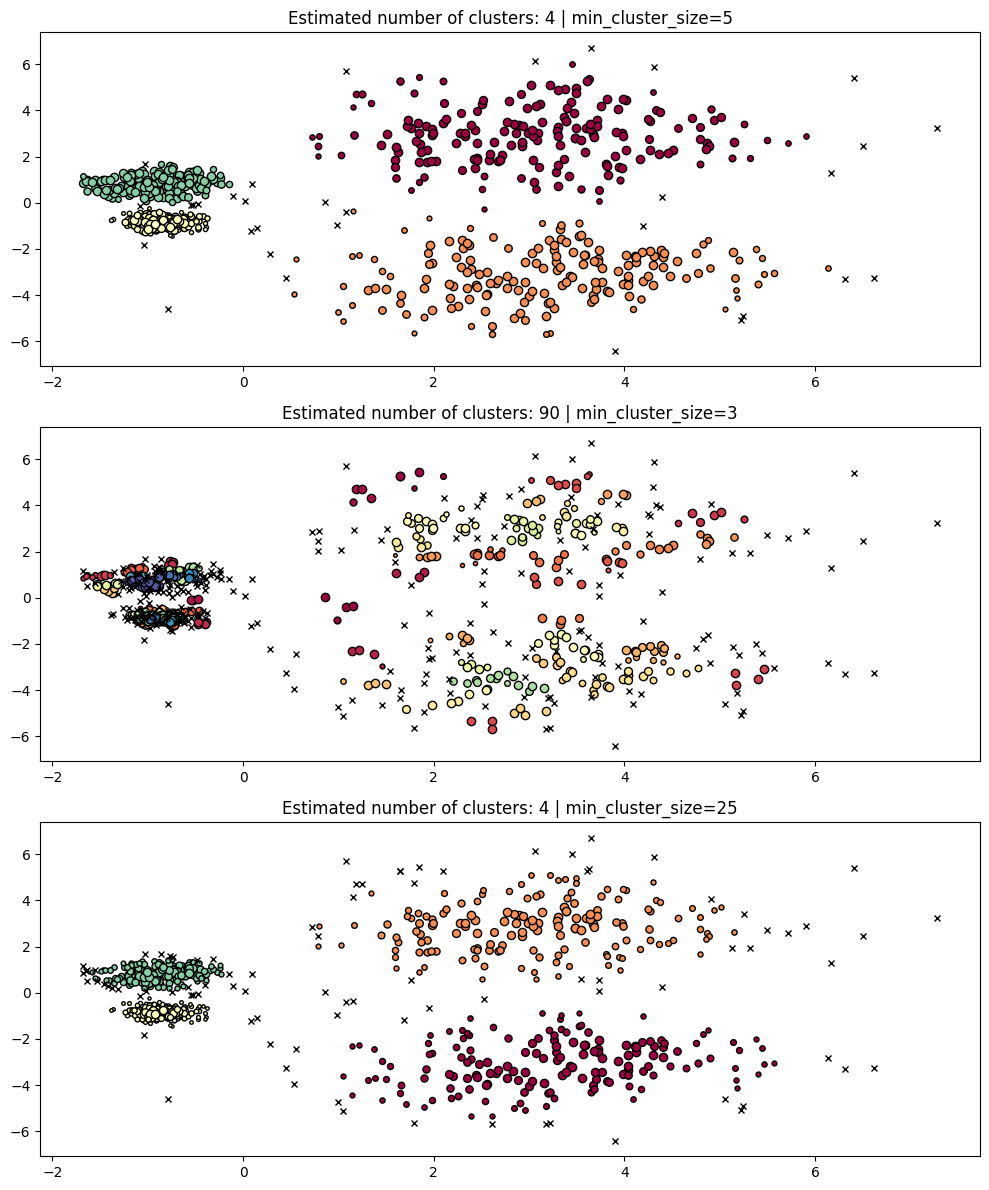

In [2]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

Saat `min_cluster_size=3`, kumpulan kecil berjumlah 3–4 titik di area renggang langsung dianggap sebagai klaster tersendiri sehingga jumlah klaster membengkak (25 klaster). Sebaliknya, pada `min_cluster_size=5` dan `min_cluster_size=25`, sub-klaster kecil tersebut diabaikan sebagai *noise* atau digabungkan sehingga menyisakan **4 klaster utama** yang stabil.

### Langkah 8 - Eksperimen Hyperparameter `min_samples`

Menguji perubahan `min_samples` (`5`, `3`, dan `25`) dengan nilai `min_cluster_size=20` tetap.

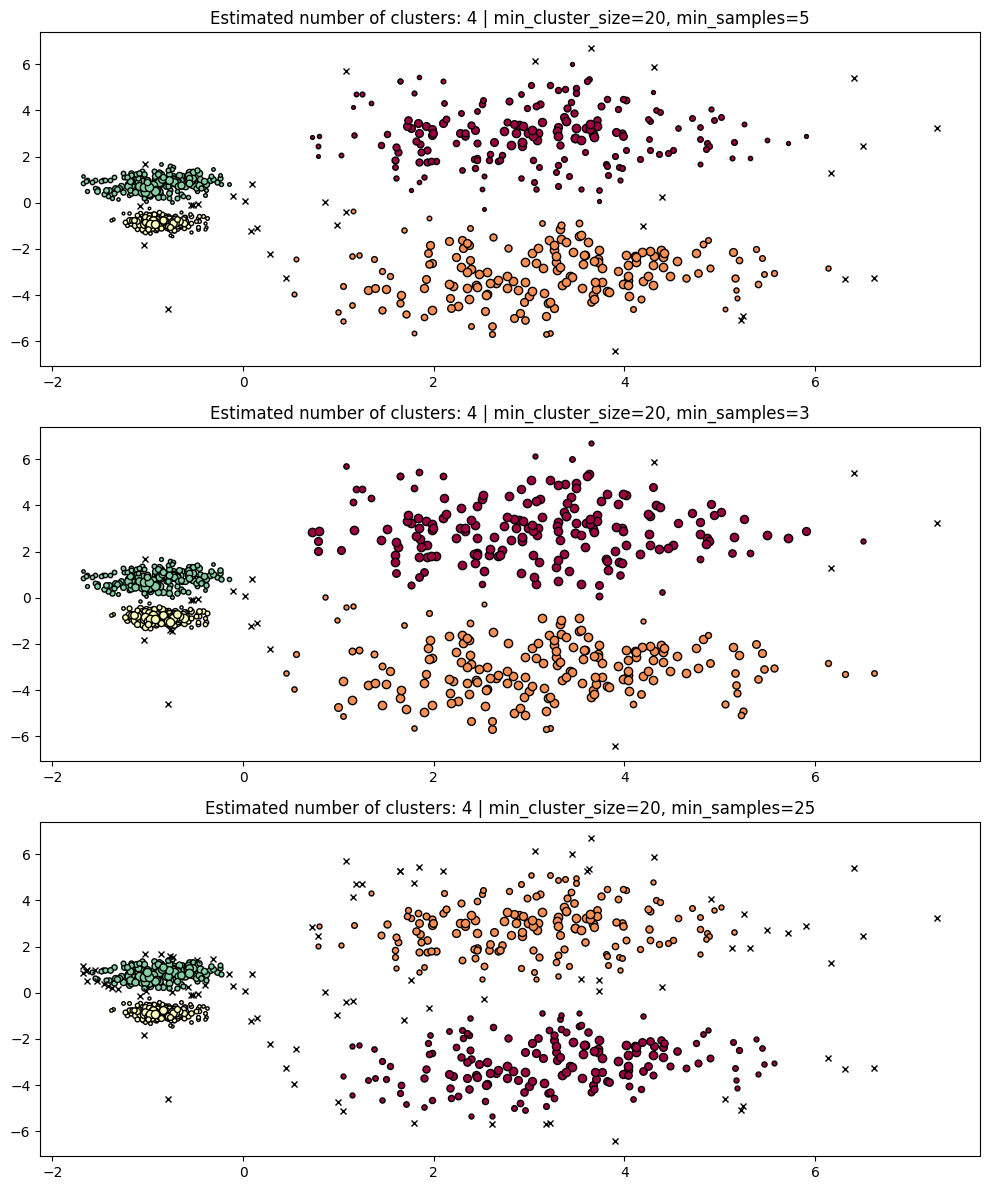

In [3]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

Terlihat bahwa semakin besar nilai `min_samples` (misalnya `min_samples=25`), algoritma menjadi semakin ketat/konservatif terhadap area yang kurang padat, sehingga makin banyak titik di pinggiran klaster renggang yang diklasifikasikan sebagai *noise* (`x` hitam), walaupun keempat klaster utama tetap terdeteksi.

### Langkah 9 - DBSCAN Clustering dari Pohon HDBSCAN (`cut_distance`)

Mengekstrak klaster daftar datar ala DBSCAN dengan memotong pohon hierarki HDBSCAN pada jarak potong (`cut_distance`) tertentu (`0.1`, `0.5`, dan `1.0`).

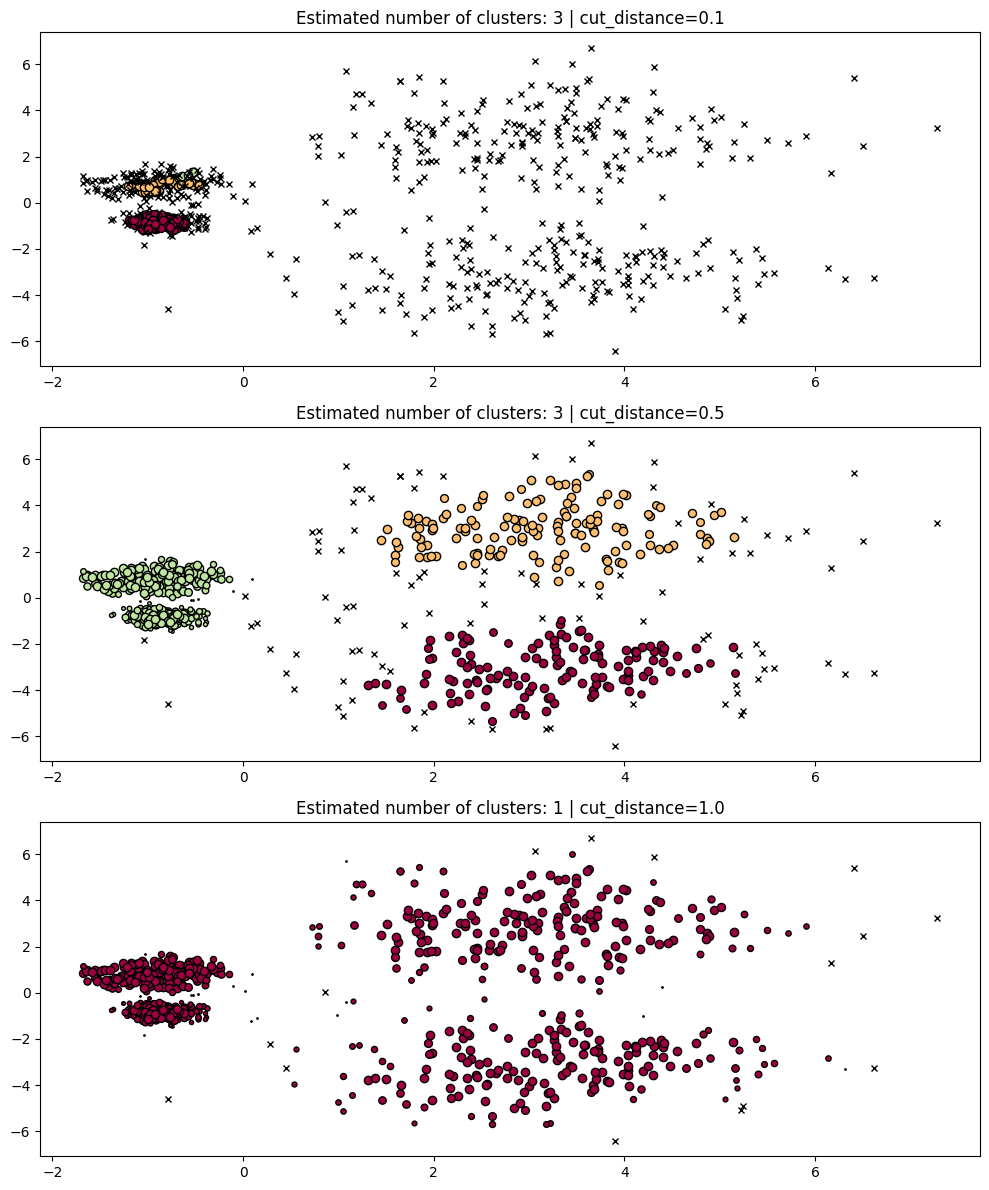

In [4]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

### Langkah 10 - Evaluasi dengan Silhouette Score

Menghitung nilai *Silhouette Score* dari hasil klasterisasi `hdb = hdbscan.HDBSCAN().fit(X)`.

In [5]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.571570919200495


### Langkah 11 - Evaluasi dengan Davies-Bouldin Index

Menghitung nilai *Davies-Bouldin Index* (DBI) dari hasil klasterisasi HDBSCAN.

In [6]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.5930750266538787


### Langkah 12 - Visualisasi Hasil Evaluasi

Membuat grafik batang perbandingan nilai *Silhouette Score* (`0.5716`) dan *Davies-Bouldin Index* (`1.5931`).

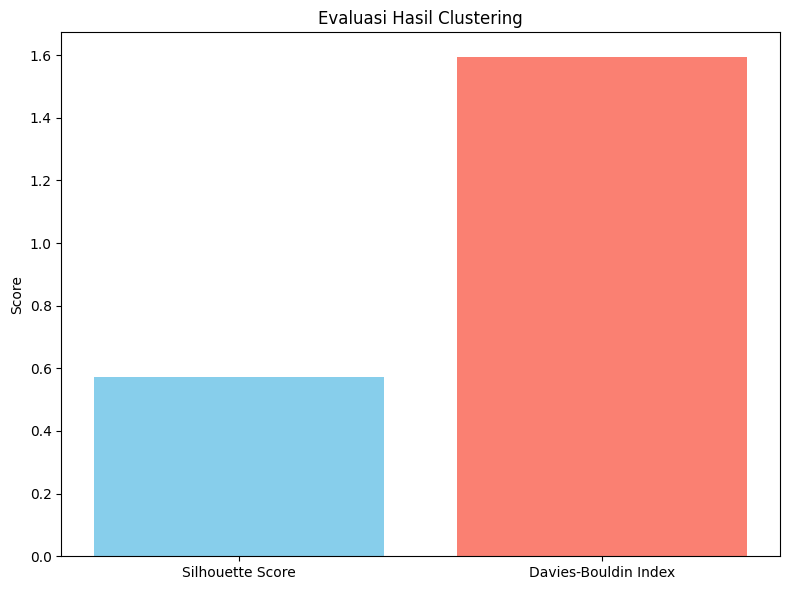

In [7]:
# Membandingkan DBI dan Silhouette Score
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()